# End-to-end: classification

This notebook runs one classification job from the question to the report: is a breast tumour malignant or benign, judged from measurements of its cells? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 8, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A woman finds a lump in her breast. Her doctor takes a few cells with a thin needle, and a lab measures the cell nuclei on a microscope image: their size, shape and texture. A pathologist then decides: **malignant** (cancer) or **benign** (not cancer).

The lab asks whether a model can give a second opinion and put the likely malignant samples first in the queue. The answer is one of two classes, so this is a **classification** problem. The two kinds of error are not equal: a missed cancer costs far more than a second look at a benign sample. So we report the **recall** for malignant samples (the share of cancers the model finds) next to accuracy.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib draws the figures, pandas holds tables, seaborn draws the confusion matrix
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# load_breast_cancer reads a data set that ships with scikit-learn
from sklearn.datasets import load_breast_cancer

The Wisconsin Diagnostic Breast Cancer data (Street, Wolberg and Mangasarian, University of Wisconsin, 1995) ship with scikit-learn, so no download is needed. `load_breast_cancer(as_frame=True)` returns the 30 measurements as a DataFrame. In the original coding, 0 means malignant; we build `is_malignant` so that 1 means malignant, the class we want to find.

In [2]:
# as_frame=True returns the measurements as a DataFrame
breast_cancer = load_breast_cancer(as_frame=True)
# X: the 30 measurements; y: 1 for malignant, 0 for benign (the original coding is the other way round)
X = breast_cancer.data
y = (breast_cancer.target == 0).astype(int).rename("is_malignant")
# shape is (number of samples, number of measurements)
print(X.shape)

(569, 30)


**What is in the data?** One row is one sample of cells from one patient's breast lump, taken with a thin needle and measured on a microscope image. For each sample, a program measured 10 properties of the cell nuclei. Each property comes in three columns: `mean …` is the average over the nuclei in the image, `… error` is the standard error of that average, and `worst …` is the mean of the three largest values. So 10 properties × 3 give the 30 columns, and the model uses all 30. The meanings below follow the dataset's own description (`load_breast_cancer().DESCR`), which gives no units: sizes are measured on the image, so compare values within one column only.

| Property | Meaning in plain words |
|---|---|
| radius | size of a nucleus: the average distance from its centre to its edge (`worst radius` is used in step 3) |
| texture | how uneven the grey shades inside the nucleus are (their standard deviation) |
| perimeter | length of the edge of the nucleus |
| area | area of the nucleus (`mean area` is used in step 5) |
| smoothness | how much the radius changes along the edge: low values mean a smooth edge (`mean smoothness` is used in step 5) |
| compactness | perimeter² / area − 1: larger for shapes less round than a circle |
| concavity | how deep the inward dents in the edge are |
| concave points | how many inward dents the edge has |
| symmetry | how symmetric the nucleus is |
| fractal dimension | how rough and complex the edge is ("coastline approximation" − 1) |

The target `is_malignant` is 1 for a malignant sample (cancer) and 0 for a benign one.

## 3 Look at the data

Thirty columns are too many to read in one table. `describe()` summarises the three columns that the text of this notebook names: their mean, standard deviation, minimum, quartiles and maximum. They show how different the scales are, which matters in step 5.

In [3]:
# The three columns named in steps 3 and 5; describe() gives count, mean, std, min, quartiles, max
X[["worst radius", "mean area", "mean smoothness"]].describe().round(3)

,worst radius,mean area,mean smoothness
count,569.000,569.000,569.000
mean,16.269,654.889,0.096
std,4.833,351.914,0.014
min,7.930,143.500,0.053
25%,13.010,420.300,0.086
50%,14.970,551.100,0.096
75%,18.790,782.700,0.105
max,36.040,2501.000,0.163


`value_counts()` shows how often each class occurs. The share tells us what accuracy a model gets by always saying "benign".

In [4]:
# How many samples of each class; rename shows the class names instead of 0 and 1
y.value_counts().rename(index={0: "benign", 1: "malignant"})

is_malignant
benign       357
malignant    212
Name: count, dtype: int64

One histogram per class shows how well a single measurement separates them. We take `worst radius`, the radius of the largest nuclei in the sample.

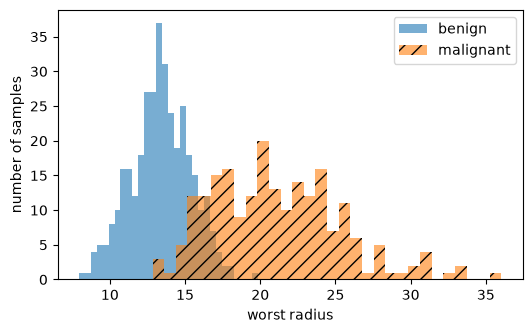

In [5]:
# Two histograms of the same measurement, one per class, drawn on top of each other
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(X.loc[y == 0, "worst radius"], bins=30, alpha=0.6, label="benign")
ax.hist(X.loc[y == 1, "worst radius"], bins=30, alpha=0.6, hatch="//", label="malignant")
ax.set_xlabel("worst radius")
ax.set_ylabel("number of samples")
ax.legend()
plt.show()

**What do you see?** Malignant samples tend to have larger nuclei, but the two histograms overlap in the middle. One measurement is not enough; the model combines all 30.

## 4 Split the data

We hold back a quarter of the samples as the **test set** and use it once, at the end. `stratify=y` keeps the share of malignant samples the same in both parts; `random_state=0` makes the split the same every time.

In [6]:
from sklearn.model_selection import train_test_split

# Keep 25% of the samples as the test set; stratify=y keeps the share of malignant samples
# the same in both parts; random_state=0 gives the same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(len(X_train), "training samples,", len(X_test), "test samples")

426 training samples, 143 test samples


## 5 Process the data

All 30 columns are numbers, so one step is enough and we need no `ColumnTransformer`. The columns are on very different scales (an area in the hundreds, a smoothness below 1). `StandardScaler` gives each a mean of 0 and a standard deviation of 1, so the penalty of logistic regression treats them alike. It learns the means and standard deviations from the training set only. The plot below shows two of these columns, `mean area` and `mean smoothness`, before and after scaling.

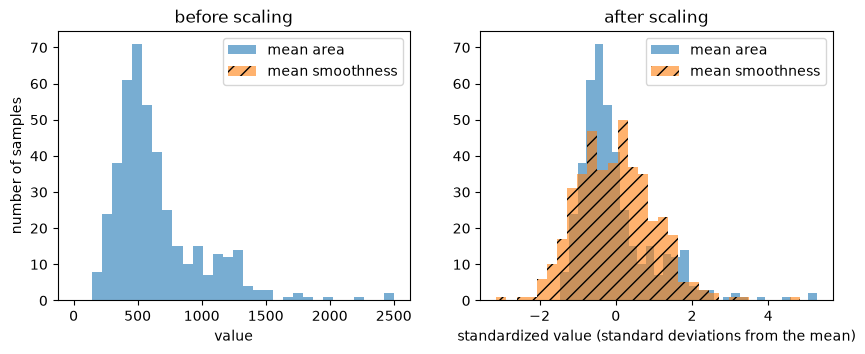

In [7]:
from sklearn.preprocessing import StandardScaler

# fit_transform learns the mean and standard deviation of each column and returns the scaled array;
# pd.DataFrame puts it back into a table with the original column names, so we can select columns by name
scaled_training_data = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X.columns)

# Left: the raw values of two columns; right: the same two columns after scaling
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 3.5))
ax_before.hist(X_train["mean area"], bins=30, alpha=0.6, label="mean area")
ax_before.hist(X_train["mean smoothness"], bins=30, alpha=0.6, hatch="//", label="mean smoothness")
ax_before.set_title("before scaling")
ax_before.set_xlabel("value")
ax_before.set_ylabel("number of samples")
ax_before.legend()

ax_after.hist(scaled_training_data["mean area"], bins=30, alpha=0.6, label="mean area")
ax_after.hist(scaled_training_data["mean smoothness"], bins=30, alpha=0.6, hatch="//", label="mean smoothness")
ax_after.set_title("after scaling")
ax_after.set_xlabel("standardized value (standard deviations from the mean)")
ax_after.legend()
plt.show()

**What do you see?** Before scaling, `mean area` runs from about 140 to 2,500. All values of `mean smoothness` lie between 0.05 and 0.16, so on the same axis its histogram is a thin sliver at 0 that you cannot see. After scaling, both columns are centred at 0 with a standard deviation of 1, and they overlap on one axis. The shape of each distribution stays the same: scaling moves and stretches the values, but it does not change their order or their skew.

Gradient boosting needs no scaling: trees split on thresholds, and a threshold works the same in any unit.

## 6 Run the pipeline

We start with the simplest model, score it, and then improve it one step at a time: logistic regression, the same model tuned with a grid search, and then gradient boosting. The five decisions of the two kinds of model:

| Decision | Logistic regression | Gradient boosting |
|---|---|---|
| Data | training samples: 30 measurements X, `is_malignant` y | the same |
| Model | a weighted sum of the scaled measurements, turned into a probability by the sigmoid | a sum of many small trees, turned into a probability by the sigmoid |
| Loss function | log loss plus an L2 penalty; `C` is the inverse of its strength | log loss |
| Optimizer | L-BFGS, a variant of gradient descent (`solver="lbfgs"`) | gradient boosting: each new tree fits the gradient of the loss |
| Evaluation | accuracy, precision, recall and F1 for malignant on the test set; a confusion matrix; `GridSearchCV` chooses `C` | the same; `GridSearchCV` chooses the tree settings |

Every model in 6.1 to 6.3 is scored in the same way. Each section compares the predicted classes with the true ones, using four measures from `sklearn.metrics`. Malignant is the positive class:

- **Accuracy** (`accuracy_score`): the share of correct answers.
- **Precision** (`precision_score`): of the samples the model calls malignant, the share that are malignant. Low precision means many false alarms.
- **Recall** (`recall_score`): of the malignant samples, the share the model finds. Low recall means missed cancers.
- **F1** (`f1_score`): one number that is high only when precision and recall are both high (their harmonic mean).

Each section then draws the **confusion matrix**. `confusion_matrix(y_test, predicted_class)` counts every combination of true and predicted class: rows are the true classes, columns the predicted ones. `sns.heatmap` draws this 2 × 2 table, with the count written in each cell (`annot=True`) and darker cells for larger counts. The diagonal holds the correct answers. The scores go into a dictionary per model (`logistic_scores`, `tuned_logistic_scores`, `boosting_scores`), from which step 7 builds its table.

### 6.1 Logistic regression

`LogisticRegression` is the most common first classifier. It learns one weight per measurement, turns the weighted sum into a probability of malignant, and predicts malignant when that probability is above 0.5. A `Pipeline` chains the scaling of step 5 and the model, so `fit` learns both from the training set. `max_iter=1000` gives the optimizer enough steps to finish.

logistic regression: accuracy 0.986, precision 1.000, recall 0.962, F1 0.981


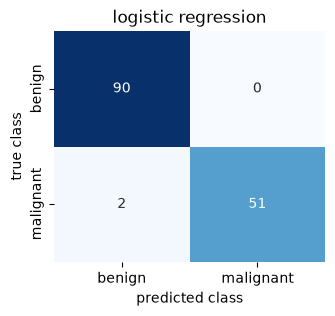

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first scale the measurements, then the model
logistic_pipeline = Pipeline([("scaling", StandardScaler()), ("logistic", LogisticRegression(max_iter=1000))])
# fit learns the scaling and the weights from the training set
logistic_pipeline.fit(X_train, y_train)
# Predict a class (0 or 1) for every test sample
logistic_predictions = logistic_pipeline.predict(X_test)
# Each metric compares the true classes with the predicted ones; step 7 builds its table from this dictionary
logistic_scores = {
    "model": "logistic regression",
    "accuracy": accuracy_score(y_test, logistic_predictions),
    "precision": precision_score(y_test, logistic_predictions),
    "recall": recall_score(y_test, logistic_predictions),
    "F1": f1_score(y_test, logistic_predictions),
}
print(f"logistic regression: accuracy {logistic_scores['accuracy']:.3f}, precision {logistic_scores['precision']:.3f}, "
      f"recall {logistic_scores['recall']:.3f}, F1 {logistic_scores['F1']:.3f}")

# A 2 × 2 array of counts: rows are true classes, columns are predicted classes (0 benign, 1 malignant)
counts = confusion_matrix(y_test, logistic_predictions)
# Draw the array as a coloured table: annot=True writes the counts, fmt="d" as whole numbers
fig, ax = plt.subplots(figsize=(3.5, 3))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"], ax=ax)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("logistic regression")
plt.show()

**What do you see?** Logistic regression classifies 141 of the 143 test samples correctly (accuracy 0.986). Read the confusion matrix row by row. Of the 90 benign samples, all 90 are called benign: no false alarms, so the precision is 1.000. Of the 53 malignant samples, the model finds 51 and misses 2, so the recall is 51 / 53 = 0.962. For a second opinion, the two missed cancers matter most.

### 6.2 Tune the model with a grid search

The penalty strength `C` is a **hyperparameter**: we choose it, the model does not learn it. A small `C` means a strong penalty and smaller weights. `GridSearchCV` tries each value in a list and keeps the best one. It scores each value on parts of the training set only, so the test set stays unseen until we score the winner.

- `{"logistic__C": [0.01, 0.1, 1, 10]}` is the grid: `logistic__C` means the argument `C` of the step named `logistic`.
- `scoring="f1"` chooses by F1, so a value wins only if it keeps both missed cancers and false alarms low.
- After the search, `best_params_` is the chosen value and `best_estimator_` is the pipeline refitted with it on the whole training set.

chosen: {'logistic__C': 1}
logistic regression, tuned: accuracy 0.986, precision 1.000, recall 0.962, F1 0.981


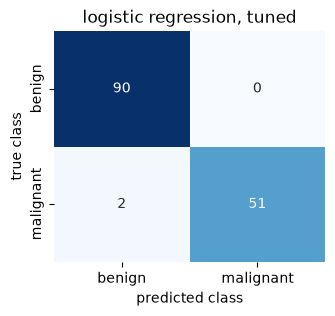

In [9]:
from sklearn.model_selection import GridSearchCV

# Try four penalty strengths and keep the one with the highest F1 on the training set
logistic_search = GridSearchCV(logistic_pipeline, {"logistic__C": [0.01, 0.1, 1, 10]}, scoring="f1")
# fit runs the whole search, then refits the best pipeline on all training samples
logistic_search.fit(X_train, y_train)
print("chosen:", logistic_search.best_params_)
# best_estimator_ is the refitted best pipeline; only now do we use the test set
# Predict a class (0 or 1) for every test sample
tuned_logistic_predictions = logistic_search.best_estimator_.predict(X_test)
# Each metric compares the true classes with the predicted ones; step 7 builds its table from this dictionary
tuned_logistic_scores = {
    "model": "logistic regression, tuned",
    "accuracy": accuracy_score(y_test, tuned_logistic_predictions),
    "precision": precision_score(y_test, tuned_logistic_predictions),
    "recall": recall_score(y_test, tuned_logistic_predictions),
    "F1": f1_score(y_test, tuned_logistic_predictions),
}
print(f"logistic regression, tuned: accuracy {tuned_logistic_scores['accuracy']:.3f}, precision {tuned_logistic_scores['precision']:.3f}, "
      f"recall {tuned_logistic_scores['recall']:.3f}, F1 {tuned_logistic_scores['F1']:.3f}")

# A 2 × 2 array of counts: rows are true classes, columns are predicted classes (0 benign, 1 malignant)
counts = confusion_matrix(y_test, tuned_logistic_predictions)
# Draw the array as a coloured table: annot=True writes the counts, fmt="d" as whole numbers
fig, ax = plt.subplots(figsize=(3.5, 3))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"], ax=ax)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("logistic regression, tuned")
plt.show()

**What do you see?** The grid search chose `C = 1`, which is the default value we used in 6.1. So the tuned model is the same model, with the same scores and the same confusion matrix. This is a useful result too: the search confirms that the default penalty was already the best of the four values for this data.

### 6.3 A more flexible model: gradient boosting

Gradient boosting adds many small decision trees, so it can learn thresholds and combinations of measurements that a weighted sum cannot. Trees need no scaling, so this pipeline has the model step only. The grid tries two learning rates (how much each new tree corrects) and two tree depths (`None` lets the trees grow until another limit stops them), four settings in all.

chosen: {'boosting__learning_rate': 0.1, 'boosting__max_depth': None}
gradient boosting, tuned: accuracy 0.979, precision 0.981, recall 0.962, F1 0.971


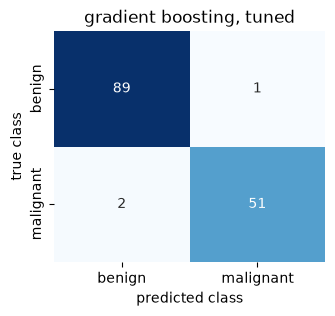

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Trees need no scaling, so the pipeline has the model step only
boosting_pipeline = Pipeline([("boosting", HistGradientBoostingClassifier(random_state=0))])
# 2 learning rates × 2 tree depths = 4 settings to try
boosting_grid = {"boosting__learning_rate": [0.05, 0.1], "boosting__max_depth": [3, None]}
boosting_search = GridSearchCV(boosting_pipeline, boosting_grid, scoring="f1")
boosting_search.fit(X_train, y_train)
print("chosen:", boosting_search.best_params_)
# Predict a class (0 or 1) for every test sample
boosting_predictions = boosting_search.best_estimator_.predict(X_test)
# Each metric compares the true classes with the predicted ones; step 7 builds its table from this dictionary
boosting_scores = {
    "model": "gradient boosting, tuned",
    "accuracy": accuracy_score(y_test, boosting_predictions),
    "precision": precision_score(y_test, boosting_predictions),
    "recall": recall_score(y_test, boosting_predictions),
    "F1": f1_score(y_test, boosting_predictions),
}
print(f"gradient boosting, tuned: accuracy {boosting_scores['accuracy']:.3f}, precision {boosting_scores['precision']:.3f}, "
      f"recall {boosting_scores['recall']:.3f}, F1 {boosting_scores['F1']:.3f}")

# A 2 × 2 array of counts: rows are true classes, columns are predicted classes (0 benign, 1 malignant)
counts = confusion_matrix(y_test, boosting_predictions)
# Draw the array as a coloured table: annot=True writes the counts, fmt="d" as whole numbers
fig, ax = plt.subplots(figsize=(3.5, 3))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"], ax=ax)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("gradient boosting, tuned")
plt.show()

**What do you see?** Gradient boosting also finds 51 of the 53 malignant samples (recall 0.962), but it raises one false alarm among the benign samples (precision 0.981). With only 426 training samples and measurements that separate the classes well, a weighted sum is enough. The more flexible model does not help here.

## 7 Report the results

One table puts the three models side by side, in the order we built them. For a second opinion on cancer, read the recall column first. Then we ask how sure these numbers are.

In [11]:
# One row per model, built from the score dictionaries of 6.1 to 6.3
test_results = pd.DataFrame([logistic_scores, tuned_logistic_scores, boosting_scores])
test_results = test_results.set_index("model").round(3)
test_results

,accuracy,precision,recall,F1
model,,,,
logistic regression,0.986,1.000,0.962,0.981
"logistic regression, tuned",0.986,1.000,0.962,0.981
"gradient boosting, tuned",0.979,0.981,0.962,0.971


### 7.1 How sure is each score?

The test set is one sample of 143 patients. Another sample would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many test sets, 95 of 100 such intervals contain the model's true score.

**A formula for one share.** Recall is a share: found cancers out of all cancers. The usual formula is the share plus or minus 1.96 standard errors:

$$\text{95\% CI} = p \pm 1.96 \sqrt{\frac{p\,(1-p)}{n}}$$

Read aloud: "p plus or minus 1.96 times the square root of p times one minus p, divided by n." Here n is the number of malignant test samples, not all 143.

The 1.96 assumes that the share would follow a bell-shaped (normal) curve over many test sets. That needs enough of both outcomes, about 10 found and 10 missed cancers. Our model misses 2, so the curve is pressed against 100% and is not bell-shaped. The **Wilson interval** does not need the bell shape. `proportion_confint(count, total, method="wilson")` from statsmodels computes it.

In [12]:
import numpy as np
from statsmodels.stats.proportion import proportion_confint

# The counts behind the recall of tuned logistic regression
chosen_predictions = logistic_search.best_estimator_.predict(X_test)
n_malignant = int((y_test == 1).sum())
n_found = int(((y_test == 1) & (chosen_predictions == 1)).sum())
recall = n_found / n_malignant

# The normal formula by hand, then the Wilson interval
standard_error = np.sqrt(recall * (1 - recall) / n_malignant)
print(f"recall {n_found}/{n_malignant} = {recall:.3f}")
print(f"normal formula: {recall - 1.96 * standard_error:.3f} to {recall + 1.96 * standard_error:.3f}")
wilson_lower, wilson_upper = proportion_confint(n_found, n_malignant, method="wilson")
print(f"Wilson:         {wilson_lower:.3f} to {wilson_upper:.3f}")

recall 51/53 = 0.962
normal formula: 0.911 to 1.014
Wilson:         0.872 to 0.990


**What do you see?** The normal formula gives 0.911 to 1.014. Its upper end lies above 1, a recall that is impossible: this is the sign that the bell shape does not fit when the model misses only 2 cancers. The Wilson interval, 0.872 to 0.990, stays below 1 and is not symmetric: it reaches 0.090 below the recall and only 0.028 above it. The real distribution has the same shape: a wall at 100% and a tail towards lower recall. Read it as: on patients like these, the model's true recall could be as low as about 87%.

**The bootstrap, for any score.** F1 and many other scores have no simple formula. The bootstrap needs none. The fitted models stay fixed; only the test rows are drawn again:

1. Draw 143 test rows **with replacement**: some patients appear twice, some not at all.
2. Compute the score on these rows.
3. Repeat 1,000 times. The middle 95% of the 1,000 scores, from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array.

In [13]:
# The test predictions of every model, computed once: the bootstrap never refits a model
fitted_models = {
    "logistic regression": logistic_pipeline,
    "logistic regression, tuned": logistic_search.best_estimator_,
    "gradient boosting, tuned": boosting_search.best_estimator_,
}
test_predictions = {}
for model_name, model in fitted_models.items():
    test_predictions[model_name] = model.predict(X_test)

# 1,000 resamples of the test rows; each row of resampled_rows holds the positions of one resample
rng = np.random.default_rng(0)
n_resamples = 1000
n_test_rows = len(y_test)
resampled_rows = rng.integers(0, n_test_rows, size=(n_resamples, n_test_rows))

# Accuracy and recall of every model on every resample
true_classes = y_test.to_numpy()
bootstrap_scores = {}
for model_name, predictions in test_predictions.items():
    bootstrap_scores[model_name] = {
        "accuracy": np.array([accuracy_score(true_classes[rows], predictions[rows]) for rows in resampled_rows]),
        "recall": np.array([recall_score(true_classes[rows], predictions[rows]) for rows in resampled_rows]),
    }

# The interval of each score: the 2.5th and the 97.5th percentile of its 1,000 values
interval_rows = []
for model_name, scores in bootstrap_scores.items():
    row = {"model": model_name}
    for score_name, values in scores.items():
        lower, upper = np.percentile(values, [2.5, 97.5])
        row[score_name] = test_results.loc[model_name, score_name]
        row[f"{score_name} 95% CI"] = f"{lower:.3f} to {upper:.3f}"
    interval_rows.append(row)
score_intervals = pd.DataFrame(interval_rows).set_index("model")
score_intervals

,accuracy,accuracy 95% CI,recall,recall 95% CI
model,,,,
logistic regression,0.986,0.965 to 1.000,0.962,0.904 to 1.000
"logistic regression, tuned",0.986,0.965 to 1.000,0.962,0.904 to 1.000
"gradient boosting, tuned",0.979,0.951 to 1.000,0.962,0.904 to 1.000


**What do you see?** Every interval is wide. With 143 patients, one error more or less moves the accuracy by 0.007; with 53 cancers, one more or one fewer missed cancer moves the recall by 0.019. The intervals of the three models overlap almost completely.

The bootstrap interval of the recall ends at 1.000. In about 13 of 100 resamples, neither of the two missed cancers is drawn, so the recall is 1.000. With so few errors the bootstrap of a share is unreliable at its edge. For a share such as recall or accuracy, report the Wilson interval of the cell above; use the bootstrap for scores that have no formula, and for differences.

### 7.2 Is one model really better? The interval of the difference

The intervals of the models overlap. Many people read this as "the models are equally good", but that is a common mistake. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare Anna and Ben, you compare them on the same exam: the difference.

Our models are in the same situation: all of them are scored on the **same** 143 patients. A resample with many clear cases raises every model; a resample with many borderline cases lowers every model. This shared luck makes each interval wide, and it cancels when we subtract one score from the other.

So we compute the **gain** of each step on every resample, with the same rows for both models: the score of the later model minus the score of the earlier one. The middle 95% of the 1,000 gains is the **95% interval of the difference**:

- the interval lies above 0: the later model is better; below 0: it is worse;
- the interval contains 0: on this test set we cannot tell the two models apart.

In [14]:
# Each step of section 6, as (short label, earlier model, later model)
steps = [("logistic → tuned logistic", "logistic regression", "logistic regression, tuned"),
         ("tuned logistic → boosting", "logistic regression, tuned", "gradient boosting, tuned")]

gain_rows = []
for label, earlier, later in steps:
    row = {"step": label}
    for score_name in ["accuracy", "recall"]:
        # The same resampled rows for both models, so every gain compares them on the same patients
        gains = bootstrap_scores[later][score_name] - bootstrap_scores[earlier][score_name]
        lower, upper = np.percentile(gains, [2.5, 97.5])
        row[f"gain in {score_name}"] = round(test_results.loc[later, score_name] - test_results.loc[earlier, score_name], 3)
        row[f"{score_name} gain 95% CI"] = f"{lower:+.3f} to {upper:+.3f}"
    gain_rows.append(row)
score_gains = pd.DataFrame(gain_rows).set_index("step")
score_gains

,gain in accuracy,accuracy gain 95% CI,gain in recall,recall gain 95% CI
step,,,,
logistic → tuned logistic,0.000,+0.000 to +0.000,0.0,+0.000 to +0.000
tuned logistic → boosting,-0.007,-0.021 to +0.000,0.0,+0.000 to +0.000


A histogram of the 1,000 accuracy gains of the last step shows the same thing as a picture. The dashed line marks a gain of 0, "no difference".

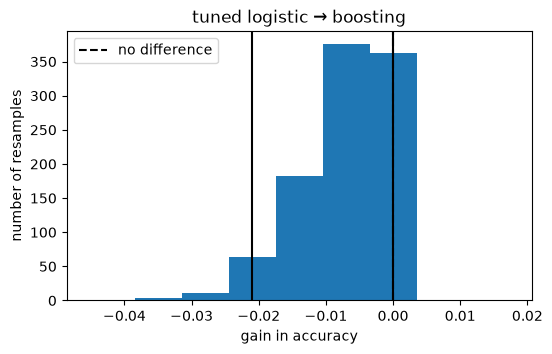

In [15]:
label, earlier, later = steps[1]
accuracy_gains = bootstrap_scores[later]["accuracy"] - bootstrap_scores[earlier]["accuracy"]

fig, ax = plt.subplots(figsize=(6, 3.5))
# One bar per possible gain: the gains move in steps of one patient, 1/143,
# so the bar edges lie half a step on either side of -6/143, -5/143, ..., 2/143
ax.hist(accuracy_gains, bins=(np.arange(-6, 4) - 0.5) / n_test_rows)
# The 95% interval as two solid lines, the value 0 as a dashed line
for bound in np.percentile(accuracy_gains, [2.5, 97.5]):
    ax.axvline(bound, color="black")
ax.axvline(0, color="black", linestyle="--", label="no difference")
ax.set_title(label)
ax.set_xlabel("gain in accuracy")
ax.set_ylabel("number of resamples")
ax.legend()
plt.show()

**What do you see?** The two models disagree on one patient only: a benign sample that gradient boosting flags as malignant. They find and miss exactly the same cancers, so the recall gain is 0 on every resample. The accuracy gain is 0 on the resamples that leave this patient out, about 37 of 100, and negative on all the others: gradient boosting is never ahead. The interval, −0.021 to 0.000, contains 0 (its upper end is 0), so this test set cannot show that one model is more accurate than the other. The whole difference rests on one patient. Tuning kept `C = 1`, so the first step has a gain of exactly 0 on every resample.

**Finding.** Logistic regression on the 30 scaled measurements classifies 98.6% of the test samples correctly and finds 51 of the 53 malignant ones (recall 0.962, 95% Wilson interval 0.872 to 0.990), with no false alarm. Gradient boosting finds the same cancers and differs on one benign patient only (95% interval of the accuracy gain −0.021 to 0.000), so the test set cannot tell the two models apart, and we choose the simpler logistic regression. One limitation: with 53 cancers in the test set, the true recall could be as low as about 87%, and the model has not been checked on samples from other labs; a larger, external test set is needed before any clinical use.

## 8 A recent method

Gradient boosting on trees is still the strong default for tables like this one. A newer idea is a **tabular foundation model**. TabPFN (Hollmann, Müller, Hutter and colleagues, University of Freiburg and Prior Labs, *Nature*, 2025) is a transformer trained in advance on millions of made-up tables. For a new table it predicts in one forward pass, with the training rows as its input, and it needs no tuning. It is made for small tables like this one: the 2025 paper reports it ahead of tuned gradient boosting on tables of up to 10,000 training rows.

TabPFN is not installed in the course environment. With it, the model step would read:

```python
from tabpfn import TabPFNClassifier

tabpfn_model = TabPFNClassifier(random_state=0).fit(X_train, y_train)
tabpfn_predictions = tabpfn_model.predict(X_test)
print("TabPFN: recall", recall_score(y_test, tabpfn_predictions))
```

Score it in the same way as 6.1 to 6.3: the same split, the same four scores and the confusion matrix.

> 📖 **Read more:** [TabPFN paper](https://www.nature.com/articles/s41586-024-08328-6) (Hollmann et al., *Nature* 637, 2025): how the model was trained and where it is better than gradient boosting.